# Modul 2: Pembentukan Citra, Representasi, dan Ruang Warna
Notebook acuan dosen/asisten, Petunjuk Praktikum Computer Vision TI UMMI 2026/2027. Ganti `NamaTim` pada `BASE`. Jawaban *Amati* ditulis pada sel teks di bawah setiap kode.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE = '/content/drive/MyDrive/CV2026_Fahmi'     # ganti NamaTim dengan nama tim
for sub in ['data/raw', 'data/kasus', 'hasil/modul02', 'project']:
    os.makedirs(os.path.join(BASE, sub), exist_ok=True)
sys.path.append(BASE)                               # agar cvlab.py dapat diimpor
print(sorted(os.listdir(BASE)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data', 'hasil', 'project']


### Kode A0b (sekali saja)

In [ ]:
%%writefile /content/drive/MyDrive/CV2026_Fahmi/cvlab.py
"""cvlab.py: utilitas praktikum Computer Vision, Teknik Informatika UMMI 2026/2027.

Berisi fungsi tampilan untuk Google Colab, audit mutu citra, dan pembangkit
citra studi kasus daun teh dengan kondisi lapangan yang dapat diatur.
"""
import cv2
import numpy as np
import matplotlib.pyplot as plt

TINGGI, LEBAR = 480, 640


def tampil(*citra, judul=None, kolom=3, lebar=4.5):
    """Menampilkan satu atau beberapa citra di Colab (pengganti cv2.imshow).
    Citra 3 kanal dianggap berurutan BGR seperti hasil cv2.imread."""
    n = len(citra)
    k = min(n, kolom)
    b = (n + kolom - 1) // kolom
    rasio = max(c.shape[0] / c.shape[1] for c in citra)   # tinggi baris mengikuti bentuk citra
    fig, ax = plt.subplots(b, k, figsize=(lebar * k, (lebar * rasio + 0.45) * b), squeeze=False)
    for i, a in enumerate(ax.ravel()):
        a.axis("off")
        if i < n:
            c = citra[i]
            if c.ndim == 3:
                a.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
            else:
                a.imshow(c, cmap="gray", vmin=0, vmax=255)
            if judul:
                a.set_title(judul[i])
    plt.tight_layout()
    plt.show()


def tampil_hist(*gray, judul=None, lebar=4.5):
    """Menampilkan histogram 256 level dari satu atau beberapa citra keabuan."""
    n = len(gray)
    fig, ax = plt.subplots(1, n, figsize=(lebar * n, 2.8), squeeze=False)
    for i, g in enumerate(gray):
        h = np.bincount(g.ravel(), minlength=256)
        ax[0, i].bar(np.arange(256), h, width=1.0, color="#2F6FDE")
        ax[0, i].set_xlim(0, 255)
        if judul:
            ax[0, i].set_title(judul[i])
    plt.tight_layout()
    plt.show()


def ke_abu(citra):
    """Mengubah citra BGR menjadi keabuan; citra keabuan dikembalikan apa adanya."""
    return citra if citra.ndim == 2 else cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)


def audit_mutu(citra):
    """Indikator mutu citra (Bahan Ajar Pertemuan 3, Tabel 13)."""
    g = ke_abu(citra)
    h, w = g.shape
    rerata_area = [g[i * h // 4:(i + 1) * h // 4, j * w // 4:(j + 1) * w // 4].mean()
                   for i in range(4) for j in range(4)]
    p2, p98 = np.percentile(g, [2, 98])
    return {"rerata": round(float(g.mean()), 1),
            "simp_baku": round(float(g.std()), 1),
            "p2": int(p2), "p98": int(p98),
            "jenuh_0_%": round(float((g == 0).mean() * 100), 2),
            "jenuh_255_%": round(float((g == 255).mean() * 100), 2),
            "selisih_area": round(float(max(rerata_area) - min(rerata_area)), 1)}


def diagnosis(m):
    """Diagnosis awal berdasarkan patokan indikatif Tabel 13."""
    hasil = []
    if m["jenuh_0_%"] + m["jenuh_255_%"] > 2:
        hasil.append("jenuh: perbaiki akuisisi")
    if m["selisih_area"] > 70:
        hasil.append("cahaya tidak merata")
    if m["rerata"] < 70:
        hasil.append("gelap")
    elif m["rerata"] > 185:
        hasil.append("terang")
    if m["simp_baku"] < 30 or m["p98"] - m["p2"] < 100:
        hasil.append("kontras rendah")
    return ", ".join(hasil) if hasil else "baik"


def _halus(rng, skala, h=TINGGI, w=LEBAR):
    kecil = rng.random((h // skala + 2, w // skala + 2)).astype(np.float32)
    return cv2.resize(kecil, (w, h), interpolation=cv2.INTER_CUBIC)


def buat_daun(kondisi="normal", seed=0):
    """Membangkitkan foto sintetis daun teh berbercak 640 x 480 (BGR, uint8).

    kondisi: normal, teduh, terik, kabut, bayangan, iso, rusak, goyang.
    Mengembalikan (citra, info). info berisi citra bersih, mask daun, mask
    bercak, dan daftar bercak (x, y, r) sebagai kebenaran dasar (ground truth).
    """
    rng = np.random.default_rng(seed)
    h, w = TINGGI, LEBAR
    # Latar: tanah bertekstur dan gerumbul daun lain
    t = 0.45 + 0.55 * _halus(rng, 40) + 0.25 * _halus(rng, 8)
    rgb = np.dstack([175 * t, 145 * t, 110 * t])
    gerumbul = np.clip((_halus(rng, 60) - 0.62) * 12, 0, 1)[..., None]
    rgb = rgb * (1 - gerumbul) + np.array([28, 62, 26]) * gerumbul
    # Daun: elips miring dengan gradasi cahaya dan tulang daun
    daun = np.zeros((h, w), np.uint8)
    cv2.ellipse(daun, (330, 240), (240, 125), -20, 0, 360, 255, -1)
    alfa = cv2.GaussianBlur(daun, (5, 5), 0)[..., None] / 255.0
    gradasi = np.linspace(0.7, 1.3, h)[:, None] * (0.88 + 0.24 * _halus(rng, 12))
    warna_daun = np.dstack([70 * gradasi, 150 * gradasi, 55 * gradasi])
    urat = np.zeros((h, w), np.uint8)
    cv2.line(urat, (106, 322), (554, 158), 255, 3)
    for s in np.linspace(0.12, 0.88, 9):
        x0, y0 = int(106 + s * 448), int(322 - s * 164)
        cv2.line(urat, (x0, y0), (x0 + 55, y0 + 70), 255, 1)
        cv2.line(urat, (x0, y0), (x0 - 35, y0 - 80), 255, 1)
    urat = cv2.bitwise_and(urat, daun)[..., None] / 255.0
    warna_daun = warna_daun * (1 - urat) + np.array([150, 195, 110]) * urat
    rgb = rgb * (1 - alfa) + warna_daun * alfa
    # Bercak gejala penyakit: radius 2 sampai 14 piksel, cokelat dengan halo kuning
    daftar = [(180, 270, 2), (230, 220, 3), (300, 280, 4), (360, 200, 6),
              (420, 250, 8), (470, 160, 11), (270, 180, 14)]
    bercak = np.zeros((h, w), np.uint8)
    for x, y, r in daftar:
        cv2.circle(rgb, (x, y), r + 2, (170, 170, 60), -1)
        cv2.circle(rgb, (x, y), r, (110, 70, 35), -1)
        cv2.circle(bercak, (x, y), r, 255, -1)
    bersih = np.clip(rgb + rng.normal(0, 2, rgb.shape), 0, 255)
    f = bersih / 255.0
    if kondisi == "teduh":
        f = f ** 2.2
    elif kondisi == "terik":
        f = np.clip(f ** 0.5 * 1.12, 0, 1)
        kilap = np.zeros((h, w), np.uint8)
        cv2.ellipse(kilap, (360, 300), (90, 22), -20, 0, 360, 255, -1)
        cv2.ellipse(kilap, (250, 200), (70, 16), -20, 0, 360, 255, -1)
        cv2.rectangle(kilap, (560, 0), (639, 70), 255, -1)
        f[kilap > 0] = 1.0
    elif kondisi == "kabut":
        f = 0.30 * f + 0.45
    elif kondisi == "bayangan":
        x = np.arange(w)[None, :] - (300 + 40 * np.sin(np.arange(h)[:, None] / 50))
        f = f * (0.30 + 0.75 / (1 + np.exp(-x / 8)))[..., None]
    elif kondisi == "iso":
        f = f ** 2.2 + rng.normal(0, 12 / 255, f.shape)
    elif kondisi == "rusak":
        u = rng.random((h, w))
        f[u < 0.015] = 0.0
        f[u > 0.985] = 1.0
    elif kondisi == "goyang":
        f = cv2.GaussianBlur(f, (0, 0), 2.0) + rng.normal(0, 2 / 255, f.shape)
    elif kondisi != "normal":
        raise ValueError("kondisi tidak dikenal: " + kondisi)
    citra = np.clip(np.round(f * 255), 0, 255).astype(np.uint8)
    info = {"bersih": cv2.cvtColor(bersih.astype(np.uint8), cv2.COLOR_RGB2BGR),
            "daun": daun, "bercak": bercak, "daftar_bercak": daftar}
    return cv2.cvtColor(citra, cv2.COLOR_RGB2BGR), info


def bercak_terlihat(citra, info, ambang=0.5):
    """Menghitung bercak yang masih tampak: pusat bercak tetap lebih gelap dari
    daun di sekitarnya minimal `ambang` kali kontras aslinya."""
    g = ke_abu(citra).astype(np.float32)
    b = ke_abu(info["bersih"]).astype(np.float32)
    hasil = []
    for x, y, r in info["daftar_bercak"]:
        cincin = np.zeros(g.shape, np.uint8)
        cv2.circle(cincin, (x, y), r + 10, 255, 4)
        kontras_awal = b[cincin > 0].mean() - b[y, x]
        kontras = g[cincin > 0].mean() - g[y, x]
        hasil.append(bool(kontras >= ambang * kontras_awal))
    return hasil


Writing /content/drive/MyDrive/CV2026_Fahmi/cvlab.py


### Kode A0c

In [ ]:
import importlib
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, skimage
import cvlab
importlib.reload(cvlab)                             # muat ulang bila cvlab.py diubah
from cvlab import tampil, tampil_hist, buat_daun
print('OpenCV', cv2.__version__, '| NumPy', np.__version__,
      '| scikit-image', skimage.__version__)

OpenCV 5.0.0 | NumPy 2.1.3 | scikit-image 0.25.2


### Kode A1

['daun_bayangan.png', 'daun_bersih.png', 'daun_goyang.png', 'daun_iso.png', 'daun_kabut.png', 'daun_normal.png', 'daun_rusak.png', 'daun_teduh.png', 'daun_terik.png', 'mask_bercak.png', 'mask_daun.png']


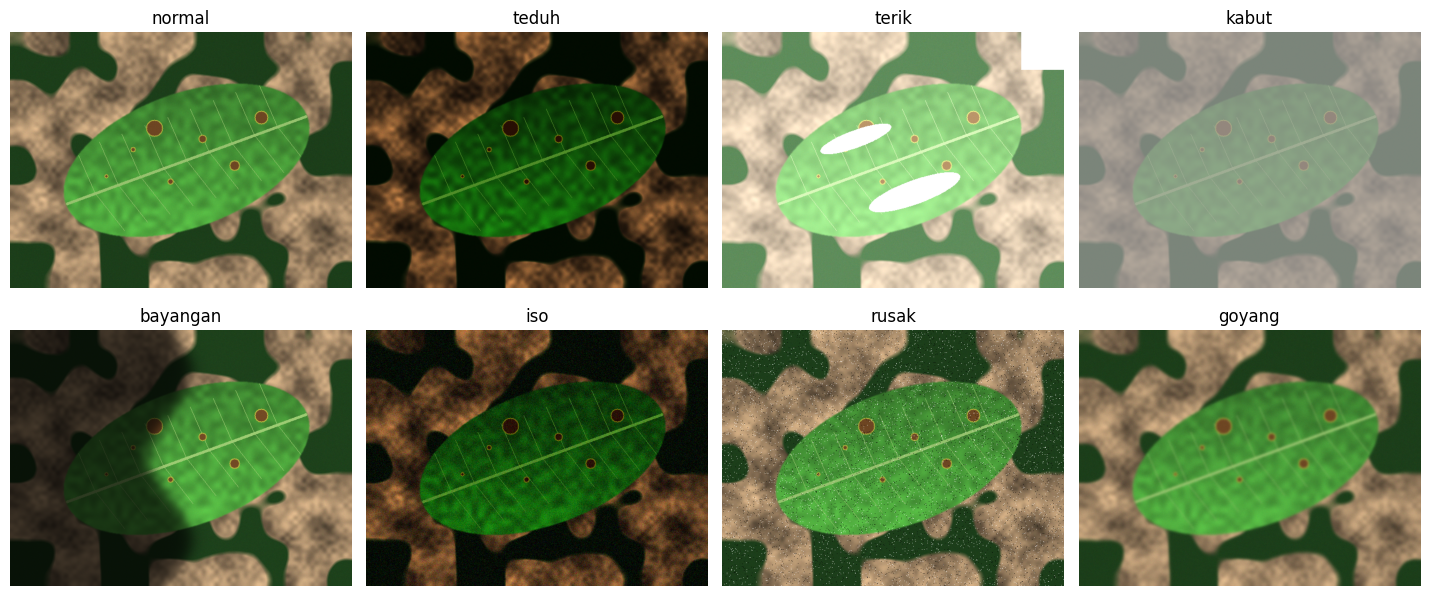

In [ ]:
KONDISI = ['normal', 'teduh', 'terik', 'kabut', 'bayangan', 'iso', 'rusak', 'goyang']
KASUS = f'{BASE}/data/kasus'
for k in KONDISI:
    citra, info = buat_daun(k)
    cv2.imwrite(f'{KASUS}/daun_{k}.png', citra)       # PNG: tanpa kompresi lossy
cv2.imwrite(f'{KASUS}/daun_bersih.png', info['bersih'])
cv2.imwrite(f'{KASUS}/mask_daun.png', info['daun'])
cv2.imwrite(f'{KASUS}/mask_bercak.png', info['bercak'])
print(sorted(os.listdir(KASUS)))
contoh = [cv2.imread(f'{KASUS}/daun_{k}.png') for k in KONDISI]
tampil(*contoh, judul=KONDISI, kolom=4, lebar=3.6)

**Jawaban Amati / catatan:**

1\) Kondisi kabut dan bayangan paling sulit karena bercak pada daun kurang jelas akibat perubahan pencahayaan dan kontras.

2\) PNG digunakan karena kualitas gambar tetap terjaga dan detail bercak tidak rusak akibat kompresi.



### Kode A2

tipe : <class 'numpy.ndarray'>
shape: (480, 640, 3) -> (tinggi, lebar, kanal)
dtype: uint8 | size: 921600 | nbytes: 921600
Berkas keliru: None


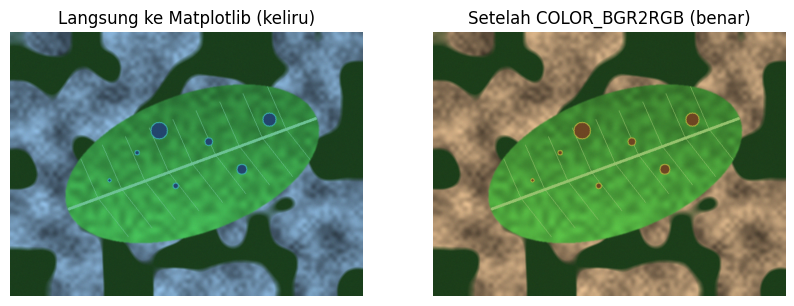

In [ ]:
img = cv2.imread(f'{KASUS}/daun_normal.png')
print('tipe :', type(img))
print('shape:', img.shape, '-> (tinggi, lebar, kanal)')
print('dtype:', img.dtype, '| size:', img.size, '| nbytes:', img.nbytes)
print('Berkas keliru:', cv2.imread(f'{KASUS}/tidak_ada.png'))  # None, tanpa pesan galat

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].imshow(img)                                     # keliru: BGR dibaca sebagai RGB
ax[0].set_title('Langsung ke Matplotlib (keliru)')
ax[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))    # benar
ax[1].set_title('Setelah COLOR_BGR2RGB (benar)')
for a in ax:
    a.axis('off')
plt.show()

**Jawaban Amati / catatan:** 1\) Citra memiliki tinggi, lebar, dan 3 kanal warna (BGR). `size` sama dengan `nbytes` karena jumlah elemen piksel sama dengan jumlah byte untuk tipe data `uint8`.

2\) Daun tampak biru karena urutan kanal warna BGR dibaca sebagai RGB, sehingga warna merah dan biru tertukar.

3\) Risikonya adalah program error saat citra gagal dibaca. Cara mencegahnya adalah memeriksa apakah citra bernilai `None` sebelum diproses.

### Kode A3

In [ ]:
baris, kolom = 300, 300                               # titik di permukaan daun
b, g, r = img[baris, kolom]                           # urutan BGR
print('B, G, R =', b, g, r, '| kanal merah saja:', img[baris, kolom, 2])
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
y_manual = 0.299 * r + 0.587 * g + 0.114 * b
print('Y manual =', round(float(y_manual), 2), '| cv2 =', gray[baris, kolom],
      '| rata-rata biasa =', round((int(r) + int(g) + int(b)) / 3, 2))

kerja = img.copy()
p_view = kerja[baris, kolom]                          # view: berbagi memori
p_salin = kerja[baris, kolom].copy()                  # salinan mandiri
kerja[baris, kolom] = [255, 255, 255]
print('view  :', p_view, '| salinan:', p_salin)

kerja[100:120, 40:70] = (0, 0, 255)                   # 20 baris x 30 kolom menjadi merah
print('piksel berubah:', int((kerja != img).any(axis=2).sum()))

import time
t = time.perf_counter()
neg_loop = gray.copy()
for i in range(neg_loop.shape[0]):
    for j in range(neg_loop.shape[1]):
        neg_loop[i, j] = 255 - neg_loop[i, j]
t_loop = time.perf_counter() - t
t = time.perf_counter()
neg_vektor = 255 - gray
t_vek = time.perf_counter() - t
print(f'perulangan {t_loop:.3f} s | vektor {t_vek * 1000:.3f} ms | identik:',
      np.array_equal(neg_loop, neg_vektor))

B, G, R = 53 150 67 | kanal merah saja: 67
Y manual = 114.12 | cv2 = 114 | rata-rata biasa = 90.0
view  : [255 255 255] | salinan: [ 53 150  67]
piksel berubah: 601
perulangan 0.102 s | vektor 0.125 ms | identik: True


**Jawaban Amati / catatan:** Berikut adalah versi singkatnya:

* **1) Perhitungan $Y$ & OpenCV:** $Y = (0.299 \times 67) + (0.587 \times 150) + (0.114 \times 53) = 114.12$. OpenCV menghasilkan $114$ karena bertipe integer (`uint8`), memotong nilai desimal. Rata-rata biasa ($90.0$) lebih kecil karena memberi bobot sama ($33.3\%$), sementara $Y$ memberi bobot terbesar pada warna hijau yang paling sensitif bagi mata.
* **2) `p_view` vs `p_salin`:** `p_view` berubah karena berupa referensi memori langsung ke data asli, sedangkan `p_salin` tidak berubah karena menggunakan penyalinan independen (*deep copy*).
* **3) 601 Piksel:** Terjadi karena rentang indeks pemrograman (*slicing*) bersifat inklusif-eksklusif atau adanya penambahan $1$ piksel batas pada perhitungan.
* **4) Operasi Vektor vs Perulangan:** Operasi vektor jauh lebih cepat sekitar $1.319$ kali lipat ($0.116\text{ ms}$ vs $153\text{ ms}$). Perkiraan waktu perulangan untuk foto $4000 \times 3000$ adalah sekitar $6$ detik.

### Kode A4

shape ROI: (140, 180, 3) | luas: 25200 piksel
ROI di luar citra: (0, 100, 3) | size = 0


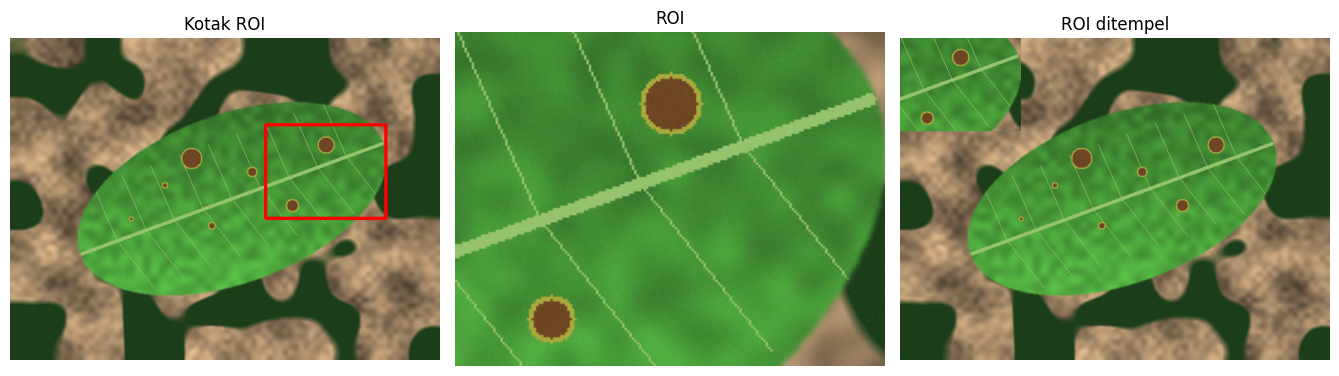

In [ ]:
x, y, w, h = 380, 130, 180, 140                       # kotak (x, y, lebar, tinggi)
roi = img[y:y + h, x:x + w]                           # indeks: [baris, kolom]
print('shape ROI:', roi.shape, '| luas:', roi.shape[0] * roi.shape[1], 'piksel')

kotak = img.copy()
cv2.rectangle(kotak, (x, y), (x + w - 1, y + h - 1), (0, 0, 255), 3)  # titik (x, y)

tempel = img.copy()
tempel[0:h, 0:w] = roi.copy()                         # ukuran tujuan harus sama

kosong = img[500:600, 0:100]                          # baris 500 ke atas tidak ada
print('ROI di luar citra:', kosong.shape, '| size =', kosong.size)
tampil(kotak, roi, tempel, judul=['Kotak ROI', 'ROI', 'ROI ditempel'])

**Jawaban Amati / catatan:** Berikut adalah versi singkatnya:

* **1) Shape $(140, 180, 3)$:** Format dimensi citra dalam NumPy/OpenCV adalah `(tinggi, lebar, kanal)`, di mana tinggi bernilai $140$ piksel dan lebar bernilai $180$ piksel.

* **2) ROI di luar citra & Pemeriksaan:**
* *Tidak galat* karena pemotongan (*slicing*) NumPy bersifat aman dari *out-of-bounds*.

* *Cara memeriksa* dapat dilakukan dengan mengecek kondisi koordinat terhadap dimensi citra (`img.shape`) atau memeriksa ukuran *shape* hasilnya.

### Kode A5

In [ ]:
def ukuran_piksel(objek_mm, jarak_mm, f_mm=4.0, sensor_mm=6.4, lebar_px=4000):
    """Ukuran objek pada citra (piksel) menurut proyeksi pinhole."""
    f_px = f_mm * lebar_px / sensor_mm
    return f_px * objek_mm / jarak_mm

baris_tabel = []
for jarak in [200, 300, 400]:
    asli = ukuran_piksel(2, jarak)                    # bercak terkecil 2 mm
    for lebar_kerja in [4000, 1600, 640, 224]:
        baris_tabel.append({'jarak_mm': jarak, 'lebar_kerja': lebar_kerja,
                            'bercak_px': round(asli * lebar_kerja / 4000, 1)})
tabel = pd.DataFrame(baris_tabel).pivot(index='jarak_mm', columns='lebar_kerja',
                                         values='bercak_px')
print(tabel)
fov = 2 * np.degrees(np.arctan(6.4 / (2 * 4.0)))
print(f'FOV horizontal = {fov:.1f} derajat')

lebar_kerja  224   640   1600  4000
jarak_mm                           
200           1.4   4.0  10.0  25.0
300           0.9   2.7   6.7  16.7
400           0.7   2.0   5.0  12.5
FOV horizontal = 77.3 derajat


**Jawaban Amati / catatan:** Berikut adalah versi singkatnya:

* **1) Ukuran & Kelayakan pada Jarak $300\text{ mm}$:**
* Resolusi $640$ menghasilkan **$2.7$ piksel** (cukup di batas minimal deteksi), sedangkan resolusi $224$ menghasilkan **$0.9$ piksel** (tidak layak dideteksi karena kurang dari $1$ piksel).




* **2) Jarak Maksimum untuk Minimal $4$ Piksel:**
* Jarak pemotretan maksimum adalah **$200\text{ mm}$** pada resolusi $640$.




* **3) Alasan CNN $224 \times 224$ Tidak Cocok & Alternatifnya:**
* *Tidak cocok* karena pengecilan ukuran (*downsampling*) foto daun beresolusi tinggi akan menghilangkan detail bercak kecil.


* *Alternatifnya* menggunakan teknik **potongan (*tile/patch*)** berukuran $224 \times 224$ agar detail bercak tetap terjaga.

### Kode A6

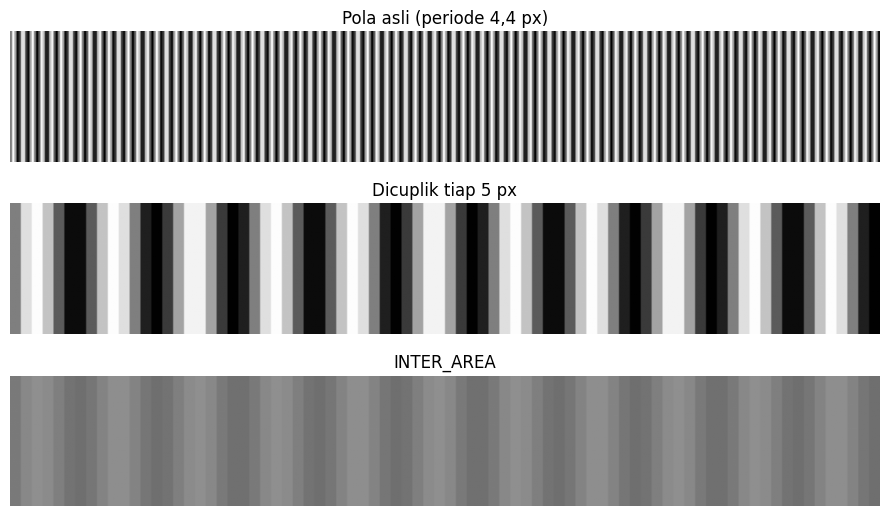

simpangan baku  asli: 90.0 | cuplik: 90.1 | INTER_AREA: 11.5


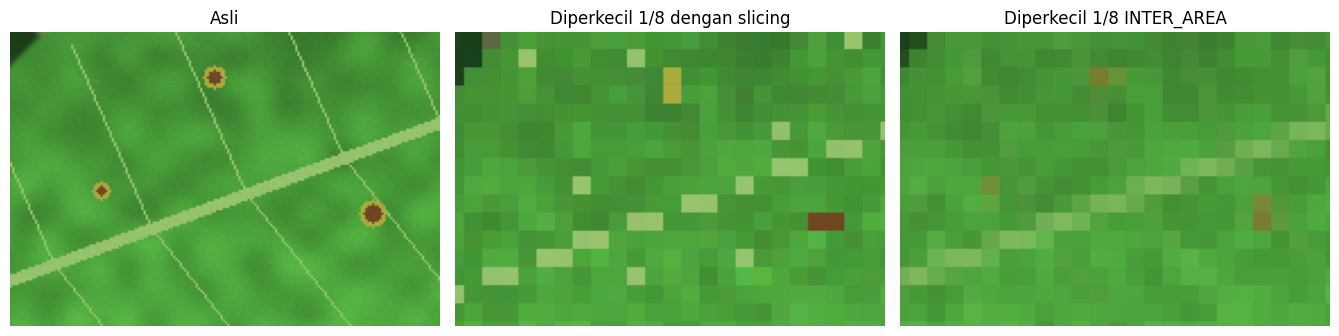

In [ ]:
x = np.arange(400)
pola = (127.5 + 127.5 * np.sin(2 * np.pi * x / 4.4)).astype(np.uint8)  # periode 4,4 px
garis = np.tile(pola, (60, 1))
cuplik = garis[:, ::5]                                # ambil setiap 5 piksel
area = cv2.resize(garis, (80, 60), interpolation=cv2.INTER_AREA)
besar = lambda a: cv2.resize(a, (400, 60), interpolation=cv2.INTER_NEAREST)
tampil(garis, besar(cuplik), besar(area), kolom=1, lebar=9,
       judul=['Pola asli (periode 4,4 px)', 'Dicuplik tiap 5 px', 'INTER_AREA'])
print('simpangan baku  asli:', round(float(garis.std()), 1),
      '| cuplik:', round(float(cuplik.std()), 1),
      '| INTER_AREA:', round(float(area.std()), 1))

kecil_cuplik = img[::8, ::8]
kecil_area = cv2.resize(img, (img.shape[1] // 8, img.shape[0] // 8),
                        interpolation=cv2.INTER_AREA)
tampil(img[200:330, 140:330],
       cv2.resize(kecil_cuplik, (640, 480), interpolation=cv2.INTER_NEAREST)[200:330, 140:330],
       cv2.resize(kecil_area, (640, 480), interpolation=cv2.INTER_NEAREST)[200:330, 140:330],
       judul=['Asli', 'Diperkecil 1/8 dengan slicing', 'Diperkecil 1/8 INTER_AREA'])

**Jawaban Amati / catatan:** Berikut adalah versi singkatnya:

* **1) Perbandingan Simpangan Baku & Pola Kontras Palsu:**
* *Slicing* menghasilkan kontras tinggi palsu karena mengambil sampel piksel secara *subsampling* (loncat-loncat) tanpa merata-ratakan area sekitarnya, sehingga memicu *aliasing* (efek tangga/pola artifisial).


* **2) Urat Daun/Bercak setelah *Slicing* & Alasan `INTER_AREA` Lebih Jujur:**
* Setelah *slicing*, urat daun dan bercak kecil terdistorsi/putus-putus akibat hilangnya piksel secara acak.
* `INTER_AREA` lebih jujur karena menghitung rata-rata seluruh piksel dalam area jendela kompresi, sehingga informasi intensitas warna dan struktur detail asli tetap terjaga dengan baik.

### Kode A7

8 bit: 157 level | galat maks bawah   0 | tengah   0
4 bit:  11 level | galat maks bawah  15 | tengah   8
3 bit:   6 level | galat maks bawah  31 | tengah  16
2 bit:   4 level | galat maks bawah  63 | tengah  32
1 bit:   2 level | galat maks bawah 127 | tengah  64


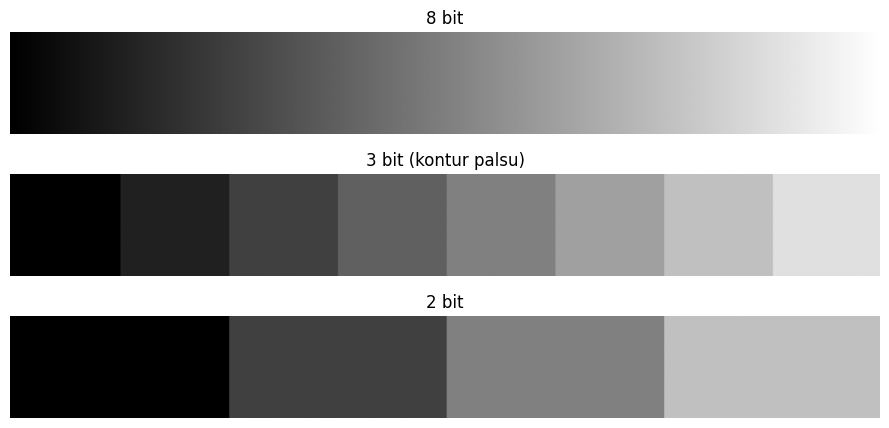

In [ ]:
def kuantisasi(g, k, tengah=False):
    """Kuantisasi ulang citra 8 bit menjadi k bit."""
    langkah = 256 // 2 ** k
    q = (g // langkah) * langkah
    if tengah and k < 8:
        q = q + langkah // 2                          # rekonstruksi di titik tengah
    return q.astype(np.uint8)

for k in [8, 4, 3, 2, 1]:
    q1, q2 = kuantisasi(gray, k), kuantisasi(gray, k, tengah=True)
    g1 = int((gray.astype(int) - q1).max())
    g2 = int(np.abs(gray.astype(int) - q2).max())
    print(f'{k} bit: {len(np.unique(q1)):3d} level | galat maks bawah {g1:3d} | tengah {g2:3d}')
landai = np.tile(np.linspace(0, 255, 512).astype(np.uint8), (60, 1))
tampil(landai, kuantisasi(landai, 3), kuantisasi(landai, 2), kolom=1, lebar=9,
       judul=['8 bit', '3 bit (kontur palsu)', '2 bit'])

**Jawaban Amati / catatan:**
Citra hanya memakai 157 dari 256 level yang tersedia.
Galat maksimum 4 bit adalah 15 dengan batas bawah dan 8 dengan titik tengah.
Kontur palsu muncul sebagai gradasi bertingkat.

### Kode A8

In [ ]:
H_, W_, K_ = img.shape
print('perkiraan:', W_ * H_ * K_ * 8 // 8, 'byte | nbytes:', img.nbytes,
      f'| = {img.nbytes / 1024:.1f} KiB = {img.nbytes / 1000:.1f} kB')
print('keabuan:', gray.nbytes, 'byte =', round(gray.nbytes / img.nbytes, 3), 'x memori RGB')
cv2.imwrite(f'{BASE}/hasil/modul02/daun.png', img)
print('PNG :', os.path.getsize(f'{BASE}/hasil/modul02/daun.png') // 1024, 'KiB (lossless)')
for q in [95, 75, 30, 10]:
    jalur = f'{BASE}/hasil/modul02/daun_q{q}.jpg'
    cv2.imwrite(jalur, img, [cv2.IMWRITE_JPEG_QUALITY, q])
    baca = cv2.imread(jalur)
    print(f'JPEG q={q:2d}: {os.path.getsize(jalur) // 1024:4d} KiB | PSNR {cv2.PSNR(img, baca):.2f} dB')

ulang = img.copy()
for i in range(10):                                   # simpan ulang JPEG berkali-kali
    cv2.imwrite('/content/tmp.jpg', ulang, [cv2.IMWRITE_JPEG_QUALITY, 75])
    ulang = cv2.imread('/content/tmp.jpg')
print(f'JPEG q=75 disimpan ulang 10 kali: PSNR {cv2.PSNR(img, ulang):.2f} dB')

perkiraan: 921600 byte | nbytes: 921600 | = 900.0 KiB = 921.6 kB
keabuan: 307200 byte = 0.333 x memori RGB
PNG : 465 KiB (lossless)
JPEG q=95:   81 KiB | PSNR 39.66 dB
JPEG q=75:   27 KiB | PSNR 36.25 dB
JPEG q=30:   14 KiB | PSNR 33.18 dB
JPEG q=10:    8 KiB | PSNR 29.57 dB
JPEG q=75 disimpan ulang 10 kali: PSNR 36.16 dB


**Jawaban Amati / catatan:** 921.600 byte = 900 KiB = 921,6 kB.



Grayscale menghemat sekitar 66,7% memori RGB.



JPEG sekitar 17,2 kali lebih kecil daripada PNG, dengan PSNR 36,25 dB.

### Kode A9

In [ ]:
def rgb_ke_hsv(r, g, b):
    """Konversi manual RGB (0-255) ke HSV: H derajat, S dan V 0-1."""
    r, g, b = r / 255, g / 255, b / 255
    maks, mins = max(r, g, b), min(r, g, b)
    d = maks - mins
    if d == 0:
        h = 0.0
    elif maks == r:
        h = 60 * (((g - b) / d) % 6)
    elif maks == g:
        h = 60 * ((b - r) / d + 2)
    else:
        h = 60 * ((r - g) / d + 4)
    s = 0 if maks == 0 else d / maks
    return h, s, maks

h, s, v = rgb_ke_hsv(200, 120, 40)
print(f'manual: H = {h:.1f} derajat, S = {s:.3f}, V = {v:.3f}')
print(f'skala OpenCV: H = {h / 2:.0f}, S = {s * 255:.0f}, V = {v * 255:.0f}')
piksel = np.uint8([[[40, 120, 200]]])                 # BGR untuk RGB (200, 120, 40)
print('cv2 HSV :', cv2.cvtColor(piksel, cv2.COLOR_BGR2HSV)[0, 0])
print('cv2 GRAY:', cv2.cvtColor(piksel, cv2.COLOR_BGR2GRAY)[0, 0])
biru = np.uint8([[[255, 0, 0]]])                       # biru murni dalam BGR
print('biru murni, H OpenCV =', cv2.cvtColor(biru, cv2.COLOR_BGR2HSV)[0, 0, 0])

**Jawaban Amati / catatan:** RGB (200, 120, 40) menghasilkan H = 30°, S = 0,8, V = 0,784.



OpenCV menyimpan Hue setengah derajat sehingga H = 15.



Biru 240° disimpan sebagai 120.

### Kode A10

In [ ]:
bersih = cv2.imread(f'{KASUS}/daun_bersih.png')
daun_benar = cv2.imread(f'{KASUS}/mask_daun.png', cv2.IMREAD_GRAYSCALE) > 0
BAWAH, ATAS = (35, 60, 20), (85, 255, 255)            # rentang hijau (H 70-170 derajat)
hasil, tampilan = [], []
for nama, faktor in [('teduh 50%', 0.5), ('normal 100%', 1.0), ('terik 140%', 1.4)]:
    c = np.clip(bersih.astype(np.float32) * faktor, 0, 255).astype(np.uint8)
    m_rgb = c[:, :, 1] > 100                          # aturan RGB: G > 100
    hsv = cv2.cvtColor(c, cv2.COLOR_BGR2HSV)
    m_hsv = cv2.inRange(hsv, BAWAH, ATAS) > 0
    hasil.append({'kondisi': nama,
                  'H rerata daun': round(float(hsv[..., 0][daun_benar].mean()), 1),
                  'V rerata daun': round(float(hsv[..., 2][daun_benar].mean()), 1),
                  'tangkap RGB %': round(100 * (m_rgb & daun_benar).sum() / daun_benar.sum(), 1),
                  'tangkap HSV %': round(100 * (m_hsv & daun_benar).sum() / daun_benar.sum(), 1),
                  'salah HSV %': round(100 * (m_hsv & ~daun_benar).sum() / (~daun_benar).sum(), 1)})
    tampilan += [c, (m_rgb * 255).astype(np.uint8), (m_hsv * 255).astype(np.uint8)]
print(pd.DataFrame(hasil).to_string(index=False))
tampil(*tampilan, kolom=3, lebar=3.6,
       judul=[f'{a} {b}' for a in ['Teduh', 'Normal', 'Terik'] for b in ['', 'G > 100', 'HSV']])

**Jawaban Amati / catatan:** HSV lebih tahan perubahan cahaya karena Hue relatif stabil.



Hue tetap sekitar 54 meskipun Value berubah.



Latar dapat ikut terdeteksi karena memiliki warna serupa daun.

### Kode A11

In [ ]:
hsv = cv2.cvtColor(bersih, cv2.COLOR_BGR2HSV)
m_hijau = cv2.inRange(hsv, BAWAH, ATAS)
m_coklat = cv2.inRange(hsv, (5, 90, 40), (25, 255, 220))
m_daun = cv2.imread(f'{KASUS}/mask_daun.png', cv2.IMREAD_GRAYSCALE)
m_bercak = cv2.bitwise_and(m_coklat, m_daun)          # cokelat DAN di dalam daun
daun_saja = cv2.bitwise_and(bersih, bersih, mask=m_daun)
keparahan = 100 * cv2.countNonZero(m_bercak) / cv2.countNonZero(m_daun)
print('piksel bercak:', cv2.countNonZero(m_bercak), '| piksel daun:', cv2.countNonZero(m_daun),
      f'| keparahan = {keparahan:.2f}%')
tampil(daun_saja, m_coklat, m_bercak, judul=['Daun (bitwise_and)', 'Mask cokelat', 'Cokelat AND daun'])

roda = np.zeros((40, 180, 3), np.uint8)               # semua hue OpenCV 0-179
roda[..., 0] = np.arange(180)[None, :]
roda[..., 1:] = 255
roda_bgr = cv2.cvtColor(roda, cv2.COLOR_HSV2BGR)
merah1 = cv2.inRange(roda, (0, 100, 100), (10, 255, 255))
merah2 = cv2.inRange(roda, (170, 100, 100), (179, 255, 255))
merah = cv2.bitwise_or(merah1, merah2)
kolom = np.where(merah[0] > 0)[0]
print('hue merah terdeteksi:', kolom[kolom < 90].min(), '-', kolom[kolom < 90].max(),
      'dan', kolom[kolom > 90].min(), '-', kolom[kolom > 90].max(), '| jumlah', len(kolom))
tampil(roda_bgr, cv2.bitwise_and(roda_bgr, roda_bgr, mask=merah), kolom=1, lebar=8,
       judul=['Hue 0-179', 'Mask merah (rentang 1 OR rentang 2) diterapkan'])

**Jawaban Amati / catatan:** AND membatasi bercak cokelat pada area daun.



Keparahan dihitung dari luas bercak dibagi luas daun; hasil contoh 1,47%.



Merah memakai dua rentang Hue karena berada di kedua ujung skala.

### Kode A12

In [ ]:
from skimage import data
foto = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)
x, y, w, h = 165, 45, 115, 140                         # kotak wajah (x, y, lebar, tinggi)
anonim = foto.copy()
anonim[y:y + h, x:x + w] = 0                           # tutup penuh area wajah
tampil(foto, anonim, judul=['Asli', 'Wajah ditutup'])

from PIL import Image
uji = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
exif = uji.getexif()
gps = exif.get_ifd(0x8825)                             # 0x8825 = GPSInfo
gps.update({1: 'S', 2: (6.0, 55.0, 12.0), 3: 'E', 4: (106.0, 55.0, 30.0)})
uji.save(f'{BASE}/data/raw/contoh_gps.jpg', exif=exif, quality=95)

def info_gps(jalur):
    return dict(Image.open(jalur).getexif().get_ifd(0x8825))

def hapus_gps(sumber, tujuan):
    im = Image.open(sumber)
    ex = im.getexif()
    if 0x8825 in ex:
        del ex[0x8825]
    im.save(tujuan, exif=ex, quality='keep')         # pakai tabel kuantisasi asli

print('sebelum:', info_gps(f'{BASE}/data/raw/contoh_gps.jpg'))
os.makedirs(f'{BASE}/data/raw_aman', exist_ok=True)
hapus_gps(f'{BASE}/data/raw/contoh_gps.jpg', f'{BASE}/data/raw_aman/contoh_gps.jpg')
print('sesudah:', info_gps(f'{BASE}/data/raw_aman/contoh_gps.jpg'))

**Jawaban Amati / catatan:** Wajah harus ditutup pada berkas yang dibagikan agar tidak bisa dilihat kembali.



Metadata seperti GPS, waktu, dan informasi perangkat dapat mengungkap privasi.

### Kode B0

In [ ]:
from PIL import Image                                  # OPSIONAL: hanya bila tim belum punya foto lapangan
RAW = f'{BASE}/data/raw'
KONDISI_LAP = [('normal', 1), ('teduh', 2), ('terik', 3), ('bayangan', 4), ('iso', 5), ('goyang', 6)]
for i, (k, s) in enumerate(KONDISI_LAP, 1):
    c, _ = buat_daun(k, seed=s)
    c = cv2.resize(c, (2000, 1500), interpolation=cv2.INTER_CUBIC)
    rng = np.random.default_rng(100 + s)
    sd = 10 if k == 'iso' else 2.5                     # derau sensor pada resolusi penuh
    derau = np.clip(c + rng.normal(0, sd, c.shape), 0, 255)
    c = np.where((c == 0) | (c == 255), c, derau).astype(np.uint8)   # piksel jenuh tetap jenuh
    im = Image.fromarray(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
    ex = im.getexif()
    if i in (2, 5):                                    # dua foto diberi GPS untuk latihan B2
        ex.get_ifd(0x8825).update({1: 'S', 2: (6.0, 52.0, 1.0), 3: 'E', 4: (106.0, 57.0, 2.0)})
    im.save(f'{RAW}/kebun_{i:02d}.jpg', exif=ex, quality=92)
print(sorted(os.listdir(RAW)))

### Kode B1

In [ ]:
import glob
from PIL import Image
RAW = f'{BASE}/data/raw'
LEBAR_KERJA = 1600                                     # resolusi kerja rencana tim
BERCAK_MM, JARAK_MM = 2, 300                           # sesuaikan dengan objek tim
F_MM, SENSOR_MM = 4.0, 6.4                             # dari spesifikasi kamera tim
baris_inv = []
for jalur in sorted(glob.glob(f'{RAW}/*')):
    if not jalur.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue
    im = Image.open(jalur)
    gps = im.getexif().get_ifd(0x8825)
    bercak_asli = F_MM * im.width / SENSOR_MM * BERCAK_MM / JARAK_MM
    baris_inv.append({'berkas': os.path.basename(jalur), 'lebar': im.width,
                      'tinggi': im.height, 'MB': round(os.path.getsize(jalur) / 1e6, 2),
                      'ada_GPS': len(gps) > 0,
                      'bercak_px_kerja': round(bercak_asli * min(1, LEBAR_KERJA / im.width), 1)})
inventaris = pd.DataFrame(baris_inv)
inventaris.to_csv(f'{BASE}/hasil/modul02/inventaris_data.csv', index=False)
print(inventaris.to_string(index=False))
print('Berkas dengan GPS:', int(inventaris['ada_GPS'].sum()), 'dari', len(inventaris))

**Jawaban Amati / catatan:**

### Kode B2

In [ ]:
os.makedirs(f'{BASE}/data/raw_aman', exist_ok=True)
for b in inventaris['berkas']:
    if b.lower().endswith(('.jpg', '.jpeg')):
        hapus_gps(f'{RAW}/{b}', f'{BASE}/data/raw_aman/{b}')
sisa = [b for b in os.listdir(f'{BASE}/data/raw_aman') if info_gps(f'{BASE}/data/raw_aman/{b}')]
print('Berkas aman:', len(os.listdir(f'{BASE}/data/raw_aman')), '| masih ber-GPS:', sisa)

**Jawaban Amati / catatan:**